# 01 · Métricas de equidad desde cero

**Fairness in Graph-Based Learning · Marco Mayta**

Una predicción puede ser precisa en promedio y funcionar de manera muy distinta entre grupos. Este cuaderno parte de un problema pequeño de **clasificación de nodos** para calcular las métricas más usadas sin depender de bibliotecas especializadas de fairness.

Se trabajó con datos simulados. El grafo nos ayuda a situar el problema, pero **no entrenaremos una GNN aquí**, aún: los puntajes son generados artificialmente para aislar la interpretación de las métricas. En particular, se construyen usando la etiqueta real: esto **no sería un procedimiento de predicción válido** en un estudio empírico.

El recorrido es simple: datos → matriz de confusión → tasas por grupo → brechas → umbrales → interpretación.

## 1. Datos de partida

Cada nodo tiene un grupo `A` o `B`, una etiqueta `y` y un puntaje `score` entre 0 y 1. Una decisión positiva se obtiene cuando el puntaje supera el umbral.

La tasa de etiquetas positivas es diferente entre grupos. Además, el puntaje contiene ruido y un desplazamiento asociado al grupo. Es un escenario deliberadamente simplificado, no una representación de una población.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 1200

grupo = np.repeat(["A", "B"], n // 2)
tasa_base = np.where(grupo == "A", 0.52, 0.30)
y = rng.binomial(1, tasa_base)

ruido = rng.normal(0, 0.23, n)
score = np.clip(0.32 + 0.40 * y - 0.07 * (grupo == "B") + ruido, 0, 1)

umbral = 0.50
nodos = pd.DataFrame({"grupo": grupo, "y": y, "score": score})
nodos["pred"] = (nodos["score"] >= umbral).astype(int)

print(f"Nodos: {len(nodos)} | Umbral: {umbral:.2f}")
display(nodos.head(8))
display(nodos.groupby("grupo").agg(n=("y", "size"), prevalencia=("y", "mean"), puntaje_medio=("score", "mean")).round(3))

Nodos: 1200 | Umbral: 0.50


,grupo,y,score,pred
0,A,0,0.093414,0
1,A,1,0.522006,1
2,A,0,0.885208,1
3,A,0,0.734401,1
4,A,1,0.625298,1
5,A,0,0.236376,0
6,A,0,0.055683,0
7,A,0,0.000000,0


,n,prevalencia,puntaje_medio
grupo,,,
A,600,0.520,0.511
B,600,0.322,0.381


## 2. ¿Dónde entra el grafo?

En aprendizaje basado en grafos, los nodos pueden depender unos de otros al intercambiar información mediante aristas. La siguiente visualización representa una **subred ilustrativa** con más conexiones dentro de cada grupo que entre grupos.

Las aristas **no intervienen** en los puntajes del ejemplo. Más adelante, otro notebook estudiará cómo la homofilia y la agregación de vecinos sí pueden modificar las predicciones.

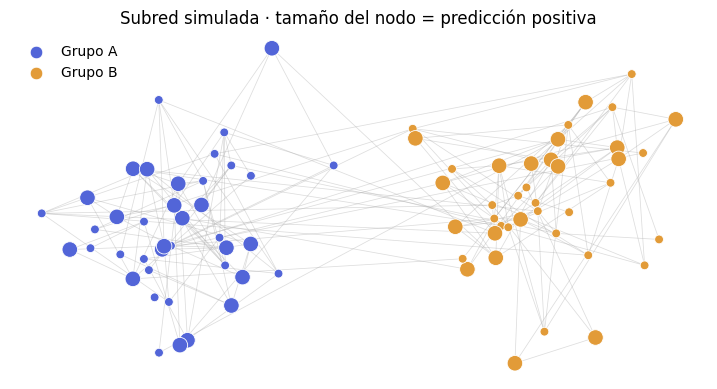

In [2]:
muestra = nodos.iloc[:40].copy()
muestra = pd.concat([muestra, nodos.iloc[600:640]]).reset_index(drop=True)

pos = np.column_stack([
    np.where(muestra["grupo"].eq("A"), -1.0, 1.0) + rng.normal(0, 0.32, len(muestra)),
    rng.normal(0, 0.75, len(muestra))
])

fig, ax = plt.subplots(figsize=(9, 4.5))
for i in range(len(muestra)):
    for j in range(i + 1, len(muestra)):
        p = 0.10 if muestra.loc[i, "grupo"] == muestra.loc[j, "grupo"] else 0.012
        if rng.random() < p:
            ax.plot(pos[[i, j], 0], pos[[i, j], 1], color="0.65", lw=0.55, alpha=0.38, zorder=1)

for g, color in [("A", "#5265d8"), ("B", "#e29b38")]:
    mask = muestra["grupo"].eq(g).to_numpy()
    ax.scatter(pos[mask, 0], pos[mask, 1], s=40 + 85 * muestra.loc[mask, "pred"].to_numpy(),
               c=color, label=f"Grupo {g}", edgecolor="white", linewidth=0.6, zorder=2)

ax.set_title("Subred simulada · tamaño del nodo = predicción positiva")
ax.legend(frameon=False)
ax.axis("off")
plt.show()

## 3. Matriz de confusión por grupo

Para cada grupo distinguimos verdaderos positivos (TP), falsos positivos (FP), verdaderos negativos (TN) y falsos negativos (FN).

| | Predicción positiva | Predicción negativa |
|---|---:|---:|
| **Etiqueta positiva** | TP | FN |
| **Etiqueta negativa** | FP | TN |

La exactitud total puede ocultar diferencias importantes: necesitamos estas cuatro cantidades **por separado** para cada grupo.

In [3]:
for g, parte in nodos.groupby("grupo"):
    matriz = pd.crosstab(parte["y"], parte["pred"], rownames=["Real"], colnames=["Predicho"])
    matriz = matriz.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    print(f"Grupo {g} (n={len(parte)})")
    display(matriz)

Grupo A (n=600)


Predicho,0,1
Real,,
0,233,55
1,58,254


Grupo B (n=600)


Predicho,0,1
Real,,
0,354,53
1,53,140


## 4. Las métricas

Con $S$ como atributo de grupo, $Y$ como etiqueta real y $\hat Y$ como predicción:

- **Paridad estadística (SP)**: $P(\hat Y=1\mid S=g)$. Compara la frecuencia de decisiones positivas.
- **Igualdad de oportunidad (EOpp)**: $\mathrm{TPR}_g=P(\hat Y=1\mid Y=1,S=g)$. Compara la recuperación de positivos reales.
- **Equalized odds (EOdds)**: requiere igualdad tanto de TPR como de $\mathrm{FPR}_g=P(\hat Y=1\mid Y=0,S=g)$.
- **Paridad predictiva**: compara $\mathrm{PPV}_g=P(Y=1\mid\hat Y=1,S=g)$.

No son sinónimos. Por ejemplo, igualar TPR no garantiza igualar las tasas de decisiones positivas.

Usaremos brechas absolutas entre A y B. Para *equalized odds*, reportaremos la **mayor** de las dos brechas (TPR y FPR); hay otras convenciones en la literatura.

In [4]:
def resumen_grupo(datos):
    y = datos["y"].to_numpy()
    pred = datos["pred"].to_numpy()

    tp = np.sum((y == 1) & (pred == 1))
    fp = np.sum((y == 0) & (pred == 1))
    tn = np.sum((y == 0) & (pred == 0))
    fn = np.sum((y == 1) & (pred == 0))

    def dividir(a, b):
        return a / b if b else np.nan

    return pd.Series({
        "n": len(datos), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Base rate": dividir(tp + fn, len(datos)),
        "SP": dividir(tp + fp, len(datos)),
        "TPR": dividir(tp, tp + fn),
        "FPR": dividir(fp, fp + tn),
        "PPV": dividir(tp, tp + fp),
        "Accuracy": dividir(tp + tn, len(datos))
    })

por_grupo = nodos.groupby("grupo")[["y", "pred"]].apply(resumen_grupo)
assert (por_grupo[["TP", "FP", "TN", "FN"]].sum(axis=1) == por_grupo["n"]).all()
display(por_grupo.round(3))

,n,TP,FP,TN,FN,Base rate,SP,TPR,FPR,PPV,Accuracy
grupo,,,,,,,,,,,
A,600.0,254.0,55.0,233.0,58.0,0.520,0.515,0.814,0.191,0.822,0.812
B,600.0,140.0,53.0,354.0,53.0,0.322,0.322,0.725,0.130,0.725,0.823


In [5]:
brecha_sp = abs(por_grupo.loc["A", "SP"] - por_grupo.loc["B", "SP"])
brecha_eopp = abs(por_grupo.loc["A", "TPR"] - por_grupo.loc["B", "TPR"])
brecha_fpr = abs(por_grupo.loc["A", "FPR"] - por_grupo.loc["B", "FPR"])
brecha_eodds = max(brecha_eopp, brecha_fpr)
brecha_ppv = abs(por_grupo.loc["A", "PPV"] - por_grupo.loc["B", "PPV"])

brechas = pd.Series({
    "Paridad estadística": brecha_sp,
    "Igualdad de oportunidad": brecha_eopp,
    "Equalized odds (máximo)": brecha_eodds,
    "Paridad predictiva": brecha_ppv
}, name="Brecha absoluta")

display((100 * brechas).round(2).to_frame("Puntos porcentuales"))
print(f"Exactitud global: {100 * (nodos['y'] == nodos['pred']).mean():.1f}%")

,Puntos porcentuales
Paridad estadística,19.33
Igualdad de oportunidad,8.87
Equalized odds (máximo),8.87
Paridad predictiva,9.66


Exactitud global: 81.8%


Una brecha cercana a cero indica similitud **según esa definición**, no justicia en un sentido general. Tampoco existe un umbral universal (por ejemplo, cinco puntos) que certifique automáticamente que un sistema es justo.

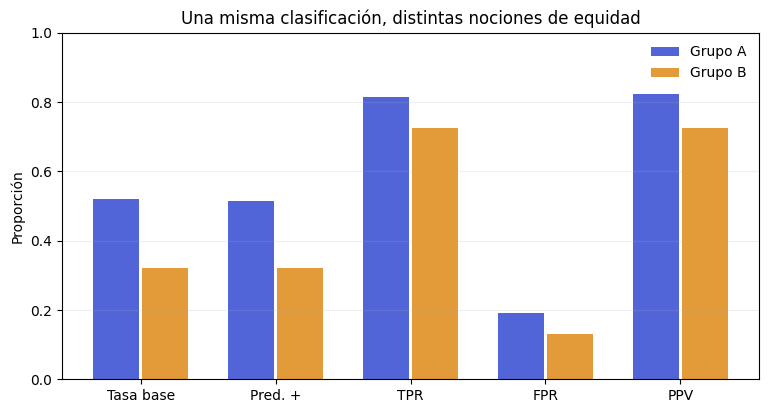

In [6]:
columnas = ["Base rate", "SP", "TPR", "FPR", "PPV"]
ejes = np.arange(len(columnas))

fig, ax = plt.subplots(figsize=(9, 4.5))
for desplazamiento, (g, color) in zip([-0.18, 0.18], [("A", "#5265d8"), ("B", "#e29b38")]):
    ax.bar(ejes + desplazamiento, por_grupo.loc[g, columnas], width=0.34, label=f"Grupo {g}", color=color)

ax.set_xticks(ejes, ["Tasa base", "Pred. +", "TPR", "FPR", "PPV"])
ax.set_ylim(0, 1)
ax.set_ylabel("Proporción")
ax.set_title("Una misma clasificación, distintas nociones de equidad")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
plt.show()

## 5. Un mismo modelo, varios umbrales

Una clasificación binaria requiere elegir un umbral $t$: $\hat Y=\mathbb{1}[\mathrm{score}\ge t]$.

Moverlo cambia la matriz de confusión, la exactitud y las brechas. Aquí aplicamos **el mismo umbral a ambos grupos**. No estamos optimizando fairness ni proponiendo un umbral de despliegue.

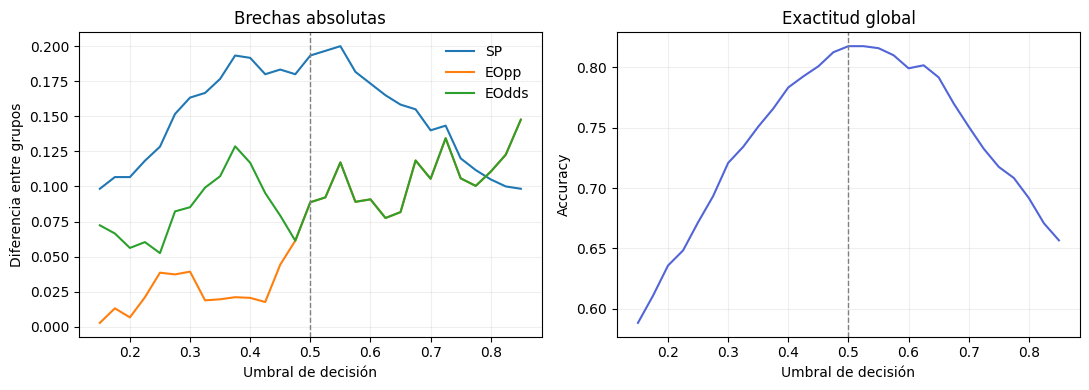

,umbral,accuracy,SP,EOpp,EOdds
14,0.5,0.818,0.193,0.089,0.089


In [7]:
filas = []
for t in np.arange(0.15, 0.851, 0.025):
    datos_t = nodos.copy()
    datos_t["pred"] = (datos_t["score"] >= t).astype(int)
    tasas = datos_t.groupby("grupo")[["y", "pred"]].apply(resumen_grupo)
    filas.append({
        "umbral": t,
        "accuracy": (datos_t["pred"] == datos_t["y"]).mean(),
        "SP": abs(tasas.loc["A", "SP"] - tasas.loc["B", "SP"]),
        "EOpp": abs(tasas.loc["A", "TPR"] - tasas.loc["B", "TPR"]),
        "EOdds": max(abs(tasas.loc["A", "TPR"] - tasas.loc["B", "TPR"]),
                     abs(tasas.loc["A", "FPR"] - tasas.loc["B", "FPR"]))
    })

curvas = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for col in ["SP", "EOpp", "EOdds"]:
    axes[0].plot(curvas["umbral"], curvas[col], label=col)
axes[0].set_title("Brechas absolutas")
axes[0].set_ylabel("Diferencia entre grupos")
axes[0].legend(frameon=False)

axes[1].plot(curvas["umbral"], curvas["accuracy"], color="#5265d8")
axes[1].set_title("Exactitud global")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.axvline(umbral, ls="--", lw=1, color="0.5")
    ax.set_xlabel("Umbral de decisión")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(curvas.iloc[(curvas["umbral"] - 0.50).abs().argsort()[:1]].round(3))

## 6. ¿Por qué las tasas base importan?

La proporción de decisiones positivas puede escribirse como

$$
P(\hat Y=1\mid S=g) = \mathrm{TPR}_g\,P(Y=1\mid S=g) + \mathrm{FPR}_g\,[1-P(Y=1\mid S=g)].
$$

Supongamos que **ambos grupos tienen exactamente el mismo TPR y FPR**. Si sus tasas base son diferentes, la paridad estadística puede fallar aun cuando *equalized odds* se cumpla. No es un fallo de cálculo, es que las métricas preguntan cosas diferentes.

In [8]:
tpr, fpr = 0.80, 0.15
escenarios = pd.DataFrame({
    "Grupo": ["A", "B", "A", "B"],
    "Escenario": ["Tasas base iguales"] * 2 + ["Tasas base distintas"] * 2,
    "Tasa base": [0.50, 0.50, 0.55, 0.25]
})
escenarios["TPR"] = tpr
escenarios["FPR"] = fpr
escenarios["Predicción positiva"] = (tpr * escenarios["Tasa base"] + fpr * (1 - escenarios["Tasa base"]))
display(escenarios.round(3))

for nombre, parte in escenarios.groupby("Escenario", sort=False):
    diferencia = parte["Predicción positiva"].max() - parte["Predicción positiva"].min()
    print(f"{nombre}: brecha SP = {100 * diferencia:.2f} puntos; brechas TPR y FPR = 0")

,Grupo,Escenario,Tasa base,TPR,FPR,Predicción positiva
0,A,Tasas base iguales,0.50,0.8,0.15,0.475
1,B,Tasas base iguales,0.50,0.8,0.15,0.475
2,A,Tasas base distintas,0.55,0.8,0.15,0.508
3,B,Tasas base distintas,0.25,0.8,0.15,0.312


Tasas base iguales: brecha SP = 0.00 puntos; brechas TPR y FPR = 0
Tasas base distintas: brecha SP = 19.50 puntos; brechas TPR y FPR = 0


## 7. ¿Qué tan estables son las brechas?

Con muestras finitas, una diferencia observada puede variar. Repetimos el cálculo tras remuestrear nodos **dentro de cada grupo**. Es un bootstrap sencillo, útil para este generador sintético donde los nodos se generaron de forma independiente.

En un grafo real, la dependencia entre nodos puede invalidar esta aproximación; allí conviene estudiar esquemas de remuestreo que respeten la estructura de la red.

,2.5%,Mediana,97.5%
Brecha SP,14.0 pp,19.17 pp,24.67 pp
Brecha EOpp,1.78 pp,8.49 pp,16.18 pp


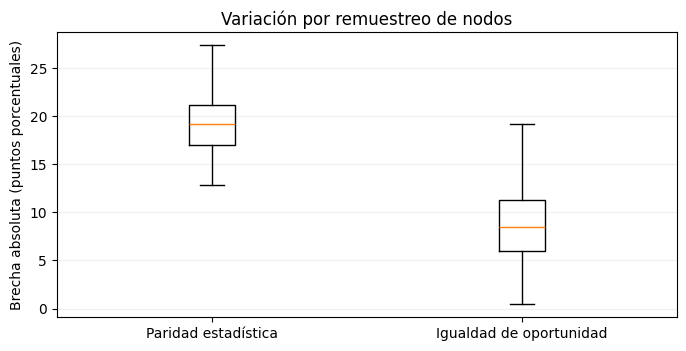

In [9]:
rng_boot = np.random.default_rng(2026)
replicas = []
for _ in range(400):
    partes = []
    for _, parte in nodos.groupby("grupo"):
        indices = rng_boot.integers(0, len(parte), len(parte))
        partes.append(parte.iloc[indices])
    tasas = pd.concat(partes).groupby("grupo")[["y", "pred"]].apply(resumen_grupo)
    replicas.append([
        abs(tasas.loc["A", "SP"] - tasas.loc["B", "SP"]),
        abs(tasas.loc["A", "TPR"] - tasas.loc["B", "TPR"])
    ])

replicas = np.asarray(replicas)
intervalos = pd.DataFrame(np.quantile(replicas, [0.025, 0.5, 0.975], axis=0).T,
                          index=["Brecha SP", "Brecha EOpp"], columns=["2.5%", "Mediana", "97.5%"])
display((100 * intervalos).round(2).astype(str) + " pp")

fig, ax = plt.subplots(figsize=(8, 3.7))
ax.boxplot(100 * replicas, showfliers=False)
ax.set_xticks([1, 2], ["Paridad estadística", "Igualdad de oportunidad"])
ax.set_ylabel("Brecha absoluta (puntos porcentuales)")
ax.set_title("Variación por remuestreo de nodos")
ax.grid(axis="y", alpha=0.2)
plt.show()

## 8. Discusión Final

Los resultados muestran que la equidad de un clasificador depende de la métrica utilizada. Un modelo puede presentar diferencias pequeñas entre grupos en términos de igualdad de oportnidad y al mismo tiempo mostrar una brecha considerable en paridad estadística. Esto no es necesariamente una contradicción, ya que cada métrica considera una aprte distinta del comportamiento del clasificador.

También observamos que las diferencias en las tasas base y la elección del umbral incluyen en los resultados. Por lo tanto, no basta solamente con calcular las métricas de manera aislada, es necesario examinar cómo se distribuyen las etiquetas y las predicciones dentro de cada grupo.

En este notebook hemos trabajado principalmente con las predicciones, aunque los datos incluyen un grafo, todavía no hemos estudiado cómo su estructurapuede influir en el comportamiento del modelo.

Como ejercicio adicional se puede repetir el análisis con umbrales de 0.35 y 0.65, o modificar la prevalencia del grupo B para observar cómo cambian las métricas.


En el siguiente notebook estudiaremos la homoflia y el sesgo estructural, incorporando las conexiones entre nodoss directamente al análisis. Ahí las aristas dejarán de ser ilustrativas y pasarán a ser parte del experimento.

---

**Lecturas:** [Hardt, Price y Srebro (2016), *Equality of Opportunity in Supervised Learning*](https://arxiv.org/abs/1610.02413) · [Barocas, Hardt y Narayanan, *Fairness and Machine Learning*](https://fairmlbook.org/).

Proyecto: [Fairness-in-GBL-MM](https://github.com/marcofmayta/Fairness-in-GBL-MM).